# v3 — Hyperparameter search + early stopping (and: do class weights belong here?)

**What v3 adds over v2.** (1) `RandomizedSearchCV` (25 draws × 3-fold) over `max_depth, learning_rate, subsample, colsample_bytree, min_child_weight`; (2) early stopping instead of a fixed tree count. Its feature pipeline (`pipelines.py`) is byte-identical to v2's, and it still trains with **balanced class weights**.

**Hypotheses.**
- **H6** — search + early stopping gives a small, real gain.
- **H5′** — from the v2 notebook: balanced weights cost accuracy (0.8034 → 0.7772 at v2). Test whether that also holds for v3, i.e. *with and without weights*.

**Protocol notes.**
- v3's *shipped* early stopping monitors the **validation fold itself**, so the reported score is optimistic. We run that, plus an **honest** version that stops on a 10% holdout carved from the training fold.
- v3 searched on *all* the data, then ran CV on the same data. We reproduce that (a 5-knob search overfits little), but the caveat stays.

| row | params | early stopping | weights |
|---|---|---|---|
| 3a | searched | none (300 trees) | no |
| 3b | searched | on val fold (**as shipped**) | no |
| 3c | searched | honest inner holdout | no |
| 3d | searched | on val fold (**as shipped**) | **yes — v3 as shipped** |
| 3e | searched | honest inner holdout | yes |

Weights effect: 3b vs 3d (shipped protocol) and 3c vs 3e (honest). Early-stopping optimism: 3b vs 3c.

In [1]:
import sys, warnings, json
sys.path.insert(0, '.')
warnings.simplefilter('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from common import *
pd.set_option('display.width', 140)
df, y, le = get_train('v3')
Flex = make_flex('v3')
feat = lambda: Flex()
ref = {r['label']: r for r in map(json.loads, RESULTS.read_text().splitlines())}
for k in ['A2 no MI cut (keep all)', '+E v2 params', '+F balanced weights  (= v2)']:
    r = next(r for r in ref.values() if r['label'] == k); print(f"reference {r['version']} {k:<30} {r['mean']:.4f} ± {r['std']:.4f}")

reference v1 A2 no MI cut (keep all)        0.8090 ± 0.0034
reference v2 +E v2 params                   0.7979 ± 0.0038
reference v2 +F balanced weights  (= v2)    0.7772 ± 0.0034


## Hyperparameter search (cached)
Run once on **all** the data, as v3 did, with v3's exact search space and settings. The result is cached in `cache/v3_search.json`, so re-running the notebook doesn't redo the ~30 min search.

In [2]:
import json as _j, time
from pathlib import Path
import xgboost as xgb
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

CACHE = Path('cache/v3_search.json'); CACHE.parent.mkdir(exist_ok=True)
DIST = {'max_depth': [4, 6, 8, 10, 12], 'learning_rate': [0.01, 0.03, 0.05, 0.08, 0.1],
        'subsample': [0.6, 0.7, 0.8, 0.9, 1.0], 'colsample_bytree': [0.6, 0.7, 0.8, 0.9, 1.0],
        'min_child_weight': [1, 3, 5, 7, 10]}
if CACHE.exists():
    S = _j.loads(CACHE.read_text())
else:
    t0 = time.time()
    X = Flex().fit_transform(df.drop(columns=[TARGET]))
    s = RandomizedSearchCV(xgb.XGBClassifier(n_estimators=300, tree_method='hist', enable_categorical=True,
                                             random_state=SEED, n_jobs=-1),
                           DIST, n_iter=25, scoring='accuracy', random_state=SEED, n_jobs=1,
                           cv=StratifiedKFold(3, shuffle=True, random_state=SEED)).fit(X, y)
    S = {'best_params': {k: (v.item() if hasattr(v, 'item') else v) for k, v in s.best_params_.items()},
         'best_score': float(s.best_score_), 'minutes': (time.time() - t0) / 60,
         'results': [{**{k: (v.item() if hasattr(v, 'item') else v) for k, v in p.items()}, 'cv_acc': float(m)}
                     for p, m in zip(s.cv_results_['params'], s.cv_results_['mean_test_score'])]}
    CACHE.write_text(_j.dumps(S))
BEST = S['best_params']
print('best params:', BEST, '| search-CV accuracy (unweighted, 300 trees):', round(S['best_score'], 4))
R = pd.DataFrame(S['results']).sort_values('cv_acc', ascending=False)
print('\nspread over the 25 draws: best %.4f, median %.4f, worst %.4f' % (R.cv_acc.max(), R.cv_acc.median(), R.cv_acc.min()))
R.head(8).round(4)

best params: {'subsample': 0.6, 'min_child_weight': 5, 'max_depth': 12, 'learning_rate': 0.03, 'colsample_bytree': 0.7} | search-CV accuracy (unweighted, 300 trees): 0.8075

spread over the 25 draws: best 0.8075, median 0.8031, worst 0.7763


,subsample,min_child_weight,max_depth,learning_rate,colsample_bytree,cv_acc
0,0.6,5,12,0.03,0.7,0.8075
7,0.7,7,10,0.08,0.6,0.8070
3,0.6,10,10,0.08,0.7,0.8063
20,0.6,7,10,0.10,0.7,0.8061
24,1.0,3,10,0.08,0.6,0.8057
10,0.8,3,12,0.03,0.8,0.8055
21,0.6,3,10,0.05,0.7,0.8052
9,0.6,3,10,0.05,0.6,0.8050


## 3a — searched params, fixed 300 trees, no weights

In [3]:
def run(label, **kw):
    sc, oof, it = cv_xgb_es(df, y, feat, BEST, **kw)
    r = log_result('v3', label, sc, note=f'mean best_iter={np.mean(it):.0f}')
    print(f"{label:<46} {r['mean']:.4f} ± {r['std']:.4f}   trees/fold {it}")
    return sc, oof, it
sc_a, oof_a, _ = run('3a searched params, 300 trees, no weights', es='none')

3a searched params, 300 trees, no weights      0.8110 ± 0.0038   trees/fold [300, 300, 300, 300, 300]


## 3b — + early stopping on the validation fold (as shipped), no weights

In [4]:
sc_b, oof_b, it_b = run('3b + ES on val fold (as shipped), no weights', es='val')

3b + ES on val fold (as shipped), no weights   0.8125 ± 0.0037   trees/fold [384, 410, 409, 396, 451]


## 3c — + honest early stopping (10% inner holdout), no weights

In [5]:
sc_c, oof_c, it_c = run('3c + honest ES (inner holdout), no weights', es='inner')

3c + honest ES (inner holdout), no weights     0.8106 ± 0.0047   trees/fold [497, 379, 351, 394, 372]


## 3d — v3 as shipped: ES on val fold **+ balanced weights**

In [6]:
sc_d, oof_d, it_d = run('3d ES on val fold + balanced weights (= v3)', es='val', balanced=True)

3d ES on val fold + balanced weights (= v3)    0.7818 ± 0.0044   trees/fold [582, 500, 598, 600, 598]


## 3e — honest ES + balanced weights

In [7]:
sc_e, oof_e, it_e = run('3e honest ES + balanced weights', es='inner', balanced=True)

3e honest ES + balanced weights                0.7800 ± 0.0056   trees/fold [547, 558, 469, 616, 464]


## Results

In [8]:
res = pd.DataFrame([r for r in map(json.loads, RESULTS.read_text().splitlines()) if r['version'] == 'v3'])
res['acc'] = res['mean'].round(4); res['fold std'] = res['std'].round(4)
res[['label', 'acc', 'fold std', 'note']].set_index('label')

,acc,fold std,note
label,,,
"3a searched params, 300 trees, no weights",0.8110,0.0038,mean best_iter=300
"3b + ES on val fold (as shipped), no weights",0.8125,0.0037,mean best_iter=410
"3c + honest ES (inner holdout), no weights",0.8106,0.0047,mean best_iter=399
3d ES on val fold + balanced weights (= v3),0.7818,0.0044,mean best_iter=576
3e honest ES + balanced weights,0.7800,0.0056,mean best_iter=531


In [9]:
def paired(a, b): d = np.array(b) - np.array(a); return f'{d.mean():+.4f}  per-fold {np.round(d, 4).tolist()}'
print('early-stopping optimism  (3b - 3c):', paired(sc_c, sc_b))
print('weights @ shipped ES     (3d - 3b):', paired(sc_b, sc_d))
print('weights @ honest ES      (3e - 3c):', paired(sc_c, sc_e))
print('search+ES vs v2 +E       (3c - ref):', round(np.mean(sc_c) - ref['+E v2 params']['mean'], 4))
print('3c vs v1 no-cut baseline:', round(np.mean(sc_c) - ref['A2 no MI cut (keep all)']['mean'], 4))

early-stopping optimism  (3b - 3c): +0.0019  per-fold [0.0014, -0.0005, 0.0025, 0.0045, 0.0017]
weights @ shipped ES     (3d - 3b): -0.0307  per-fold [-0.0292, -0.0339, -0.0299, -0.0306, -0.0298]
weights @ honest ES      (3e - 3c): -0.0306  per-fold [-0.0267, -0.0351, -0.0317, -0.0265, -0.0327]
search+ES vs v2 +E       (3c - ref): 0.0127
3c vs v1 no-cut baseline: 0.0015


In [10]:
from sklearn.metrics import recall_score
rows = [{'model': n, 'acc': (o == y).mean(), **{f'recall[{c}]': v for c, v in zip(le.classes_, recall_score(y, o, average=None))}}
        for n, o in [('3c honest ES, no weights', oof_c), ('3e honest ES, weights', oof_e), ('3d shipped (val ES + weights)', oof_d)]]
pd.DataFrame(rows).set_index('model').round(4)

,acc,recall[functional],recall[functional needs repair],recall[non functional]
model,,,,
"3c honest ES, no weights",0.8106,0.8988,0.3211,0.7783
"3e honest ES, weights",0.7800,0.8000,0.5840,0.7888
3d shipped (val ES + weights),0.7818,0.8020,0.5819,0.7911


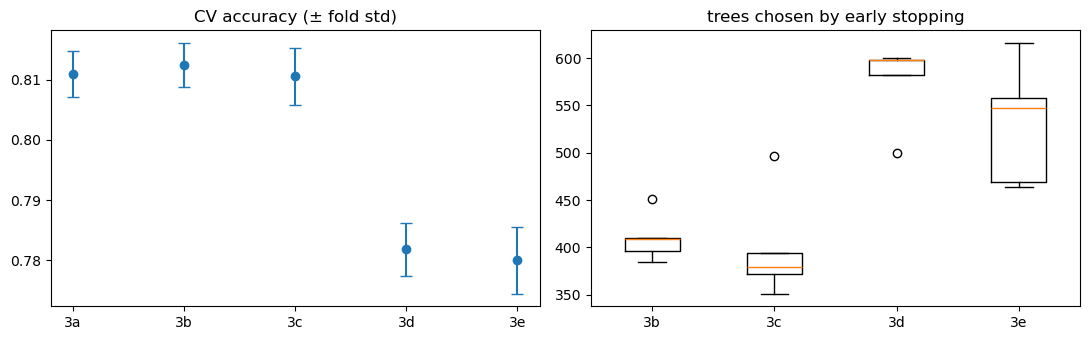

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].errorbar(range(len(res)), res['mean'], yerr=res['std'], fmt='o', capsize=4)
ax[0].set_xticks(range(len(res))); ax[0].set_xticklabels([l.split()[0] for l in res.label]); ax[0].set_title('CV accuracy (± fold std)')
ax[1].boxplot([it_b, it_c, it_d, it_e], labels=['3b', '3c', '3d', '3e']); ax[1].set_title('trees chosen by early stopping')
plt.tight_layout(); plt.show()

## Conclusion

| row | CV accuracy | notes |
|---|---|---|
| 3a searched params, 300 trees, no weights | 0.8110 ± 0.0038 | |
| 3b + ES on val fold (as shipped), no weights | 0.8125 ± 0.0037 | optimistic (ES sees the scored fold) |
| 3c + honest ES, no weights | **0.8106 ± 0.0047** | honest best |
| **3d v3 as shipped (val ES + weights)** | **0.7818 ± 0.0044** | what the repo actually produces |
| 3e honest ES + weights | 0.7800 ± 0.0056 | |

**Paired, same-fold differences**

| comparison | mean Δ | per-fold |
|---|---|---|
| weights, shipped protocol (3d − 3b) | **−0.0307** | −0.029, −0.034, −0.030, −0.031, −0.030 |
| weights, honest protocol (3e − 3c) | **−0.0306** | −0.027, −0.035, −0.032, −0.027, −0.033 |
| early-stopping optimism (3b − 3c) | +0.0019 | +0.001, −0.001, +0.003, +0.005, +0.002 |
| early stopping vs fixed 300 trees (3c − 3a) | −0.0005 | mixed signs |

- **H5′ is confirmed, again and more strongly.** Balanced weights cost **−0.031 accuracy** in all 5 folds under both protocols, versus −0.021 at v2. The stronger model pays more. It buys *needs repair* recall (0.32 → 0.58) and costs *functional* recall (0.90 → 0.80). If the leaderboard metric is accuracy, **v3 as shipped (0.782) is about 0.03 below the same code without weights (0.811)**.
- **H6 (search + early stopping) is only partly supported.**
  - *Search:* searched params beat v2's hand-picked ones by +0.013 (3a vs v2 +E 0.7979). But against v1's untuned model with all features (0.8090), the gain is **+0.002, inside the fold std**. The search mostly recovers what v2's hand-picked params lost. It does avoid bad configs: the 25 draws range 0.776 to 0.8075, median 0.803, so a few bad draws drive the spread and the top configs are close.
  - *Early stopping:* no accuracy gain (−0.0005, noise). It only saves choosing the tree count (about 400 trees at lr 0.03). Stopping on the scored fold inflates the number by about +0.002, small but real, which is why 3b looks like the best row.
- **Caveats.**
  1. The search ran on all rows before CV, so the CV numbers are slightly optimistic (5 knobs, small effect).
  2. The best `max_depth` is 12, the **edge of the search space**. Deeper trees may do better. Not tested.
  3. Native categorical features plus tuned depth-12 trees (3a 0.8110) are about equal to v1's frequency-encoded features (0.8090). The v2 representation change isn't a clear win.
  4. CV only, one seed, no leaderboard.

**Implication.** The honest best so far is **≈ 0.811**, and the most valuable change anywhere in v1–v3 is *removing* two things: the top-15 feature cut (+0.006, v1 notebook) and the class weights (+0.031). Every later version (v4–v7) still inherits the weights. The v4 notebook should therefore run **without weights** and compare against 0.811.

Next: **v4** adds `geo_cluster` (KMeans on lat/long), which is where the latitude placeholder bug could matter.